# 03 — Simulación de la operación diaria

**Práctica 4 · Logística del Valle** (punto 5 del enunciado; base de la aplicación del punto 6)

Modelamos la llegada variable de pedidos, la cola, la asignación de vehículos, el viaje de ida, la entrega y el regreso
a la bodega, y comparamos dos políticas de rutas con **los mismos pedidos**:

- **Actual:** rutas de las hojas de despacho (regreso = ida invertida).
- **Recomendada:** rutas de menor tiempo calculadas con Dijkstra, ida y regreso por separado.

El código está en `src/simulacion.py` (modelo) y `src/graficas.py` (gráficas).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import grafo as g
from src import graficas as gr
from src import simulacion as s

G = g.construir_grafo(g.cargar_matriz())
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

## 1. Descripción del modelo

Es una **simulación de eventos discretos** implementada con [SimPy](https://simpy.readthedocs.io/): el reloj salta de un
evento al siguiente y cada pedido es un proceso que espera, ocupa un vehículo y lo libera.

| Elemento | Representación |
|---|---|
| **Entidades** | Pedidos, cada uno con instante de llegada y destino |
| **Recurso** | Flota de vehículos (`simpy.Store` con los números de vehículo) |
| **Cola** | FIFO: los pedidos toman vehículo en orden de llegada |
| **Eventos** | Llegada del pedido → asignación de vehículo → entrega en el destino → regreso a N01 |
| **Tiempos de viaje** | Minutos de ida y de regreso de la ruta de cada política (deterministas) |
| **Fin** | Se reciben pedidos durante la jornada, pero la simulación **sigue** hasta atender todos |

Ciclo de vida de un pedido:

```
llega ──► ¿hay vehículo libre? ──no──► espera en cola (FIFO)
                 │ sí                         │
                 ▼                            ▼
          viaje de ida (+ descarga) ──► ENTREGA ──► regreso a N01 ──► vehículo libre
```

### Supuestos

1. Las llegadas siguen un **proceso de Poisson** con tasa constante durante la jornada.
2. Cada pedido va a uno de los 4 destinos con **probabilidad 1/4**, independiente de los demás.
3. Los tiempos de viaje son **deterministas** e iguales a los de la matriz: no hay variabilidad por tráfico.
4. El tiempo de **descarga** en el destino es 0 min por defecto (configurable en la app). La entrega se considera
   completa al llegar al destino.
5. Los vehículos son idénticos, están todos en N01 al inicio y no tienen averías, descansos ni turnos.
6. Asignar el vehículo y cargar el pedido no toma tiempo.
7. Una entrega es **puntual** si `entrega − llegada ≤ 75 min`, incluida la espera en cola.

## 2. Generación de pedidos

### Tiempos entre llegadas

"Cuatro pedidos por hora en promedio, de manera variable" se modela como un **proceso de Poisson** de tasa
λ pedidos/hora. En ese proceso, los tiempos entre llegadas consecutivas son **exponenciales** con media 60/λ minutos:

$$T_i \sim \text{Exponencial}\left(\text{media} = \tfrac{60}{\lambda}\right), \qquad t_i = t_{i-1} + T_i$$

Se generan llegadas mientras $t_i < 480$ min (8 horas). Así el **número de pedidos del día es aleatorio**
(Poisson con media 8λ) y los pedidos pueden llegar agrupados o espaciados, como en la realidad.

### Asignación de destinos

Cada pedido recibe un destino con `rng.choice(["N08", "N19", "N34", "N40"])`, es decir, uniforme con probabilidad 1/4.

Ambos pasos usan un generador `numpy.random.default_rng(semilla)`: **la misma semilla produce exactamente los mismos
pedidos**. Por eso las dos políticas se pueden comparar con pedidos idénticos.

In [2]:
p = s.Parametros(pedidos_por_hora=4, semilla=1)
pedidos = s.generar_pedidos(p.pedidos_por_hora, p.horas_recepcion, p.semilla)
print(f"Escenario normal, semilla {p.semilla}: {len(pedidos)} pedidos (esperados: {8 * p.pedidos_por_hora:g})")
pedidos.head(10)

Escenario normal, semilla 1: 28 pedidos (esperados: 32)


,pedido,llegada,destino
0,1,16.1,N19
1,2,20.7,N08
2,3,101.4,N19
3,4,106.9,N34
4,5,108.6,N19
5,6,135.6,N40
6,7,143.1,N19
7,8,151.3,N34
8,9,151.8,N40
9,10,163.2,N40


### Validación del generador

Generamos 2 000 jornadas normales y comparamos con la teoría: los tiempos entre llegadas deben ajustarse a la
exponencial de media 15 min, el número de pedidos por día debe promediar 32 y cada destino debe recibir ~25 %.

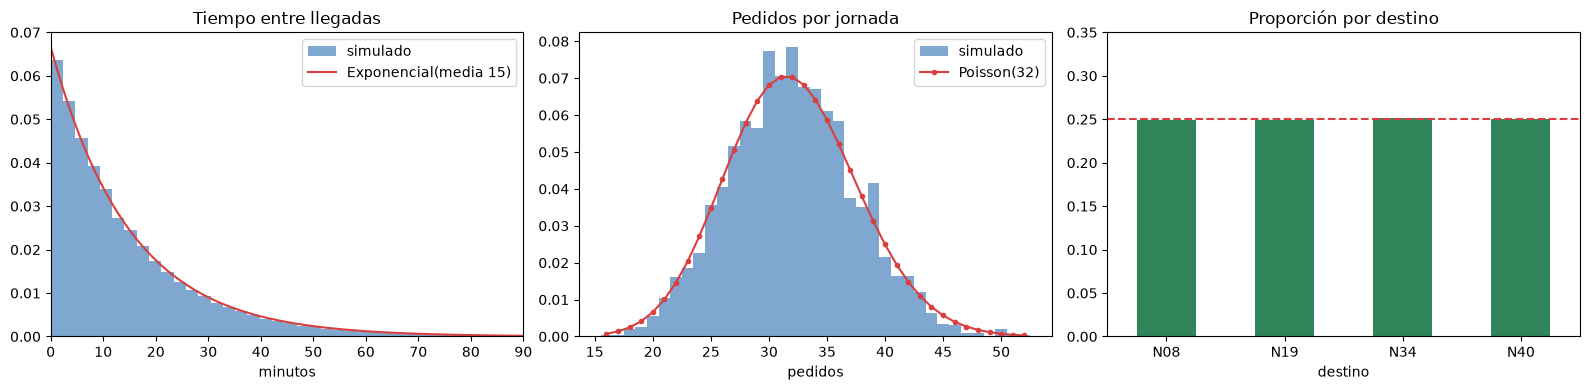

Media entre llegadas: 14.52 min (teórica 15)   Pedidos por día: 32.03 (teórico 32)


In [3]:
muestras = [s.generar_pedidos(4, 8, semilla) for semilla in range(2000)]
entre = np.concatenate([np.diff(np.r_[0, m["llegada"].to_numpy()]) for m in muestras])
por_dia = np.array([len(m) for m in muestras])
destinos = pd.concat(m["destino"] for m in muestras).value_counts(normalize=True).sort_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
x = np.linspace(0, entre.max(), 200)
axes[0].hist(entre, bins=60, density=True, alpha=0.6, color="#2b6cb0", label="simulado")
axes[0].plot(x, np.exp(-x / 15) / 15, color="#d93f3f", label="Exponencial(media 15)")
axes[0].set(title="Tiempo entre llegadas", xlabel="minutos", xlim=(0, 90))
axes[0].legend()

k = np.arange(por_dia.min(), por_dia.max() + 1)
from math import factorial, exp
axes[1].hist(por_dia, bins=np.arange(k[0] - 0.5, k[-1] + 1.5), density=True, alpha=0.6, color="#2b6cb0", label="simulado")
axes[1].plot(k, [exp(-32) * 32.0**i / factorial(i) for i in k], "o-", ms=3, color="#d93f3f", label="Poisson(32)")
axes[1].set(title="Pedidos por jornada", xlabel="pedidos")
axes[1].legend()

destinos.plot.bar(ax=axes[2], color="#2f855a", rot=0)
axes[2].axhline(0.25, color="#d93f3f", ls="--")
axes[2].set(title="Proporción por destino", ylim=(0, 0.35))
plt.tight_layout()
plt.show()

print(f"Media entre llegadas: {entre.mean():.2f} min (teórica 15)   "
      f"Pedidos por día: {por_dia.mean():.2f} (teórico 32)")

La media entre llegadas sale un poco por debajo de 15 min porque cada jornada se corta en 480 min: el intervalo que
quedaría abierto después del último pedido no se cuenta, y esos intervalos tienden a ser los largos. El número de pedidos
por día y la proporción por destino coinciden con la teoría.

## 3. Rutas de cada política

La simulación solo necesita cuánto tarda la ida y cuánto el regreso de cada destino. La política **Recomendada** se
recalcula con Dijkstra sobre la red vigente, de modo que si un tramo cambia o se cierra, sus rutas se actualizan solas.

In [4]:
filas = []
for politica in s.POLITICAS:
    rutas, _ = s.rutas_politica(G, politica)
    for d, rr in rutas.items():
        filas.append({"política": politica, "destino": d,
                      "ida (min)": rr["ida"][1], "regreso (min)": rr["regreso"][1],
                      "ciclo (min)": rr["ida"][1] + rr["regreso"][1]})
pd.DataFrame(filas).pivot(index="destino", columns="política")

ida (min)             regreso (min)             ciclo (min)  \
política    Actual Recomendada        Actual Recomendada      Actual   
destino                                                                
N08           59.0        51.0          59.0        59.0       118.0   
N19           33.0        18.0          33.0        24.0        66.0   
N34           42.0        24.0          42.0        34.0        84.0   
N40           93.0        47.0          93.0        61.0       186.0   

                      
política Recomendada  
destino               
N08            110.0  
N19             42.0  
N34             58.0  
N40            108.0

## 4. Corrida de ejemplo: día normal, semilla 1

Ambas políticas reciben **los mismos pedidos**, en los mismos instantes y con los mismos destinos.

In [5]:
p = s.Parametros(pedidos_por_hora=4, vehiculos=8, horas_recepcion=8, semilla=1)
pedidos, resultados, avisos = s.comparar(p, G)
s.tabla_metricas(resultados)

,Actual,Recomendada,Diferencia
pedidos,28.0,28.0,0.0
entregas puntuales,17.0,28.0,11.0
puntualidad (%),60.7,100.0,39.3
espera promedio (min),7.8,1.1,-6.7
espera máxima (min),53.3,14.7,-38.6
solicitud→entrega promedio (min),63.6,33.4,-30.2
solicitud→entrega máximo (min),108.5,65.7,-42.8
utilización (%),61.9,46.9,-15.1
tiempo adicional (min),57.7,11.7,-46.0
fin de la operación (min),630.7,552.7,-78.0


Primeros pedidos con la política actual (todos los tiempos en minutos desde el inicio de la jornada):

In [6]:
resultados["Actual"]["registros"].head(12)

,pedido,destino,vehiculo,llegada,inicio,entrega,retorno,espera,solicitud_a_entrega
0,1,N19,1,16.1,16.1,49.1,82.1,0.0,33.0
1,2,N08,2,20.7,20.7,79.7,138.7,0.0,59.0
2,3,N19,3,101.4,101.4,134.4,167.4,0.0,33.0
3,4,N34,4,106.9,106.9,148.9,190.9,0.0,42.0
4,5,N19,5,108.6,108.6,141.6,174.6,0.0,33.0
5,6,N40,6,135.6,135.6,228.6,321.6,0.0,93.0
6,7,N19,7,143.1,143.1,176.1,209.1,0.0,33.0
7,8,N34,8,151.3,151.3,193.3,235.3,0.0,42.0
8,9,N40,1,151.8,151.8,244.8,337.8,0.0,93.0
9,10,N40,2,163.2,163.2,256.2,349.2,0.0,93.0


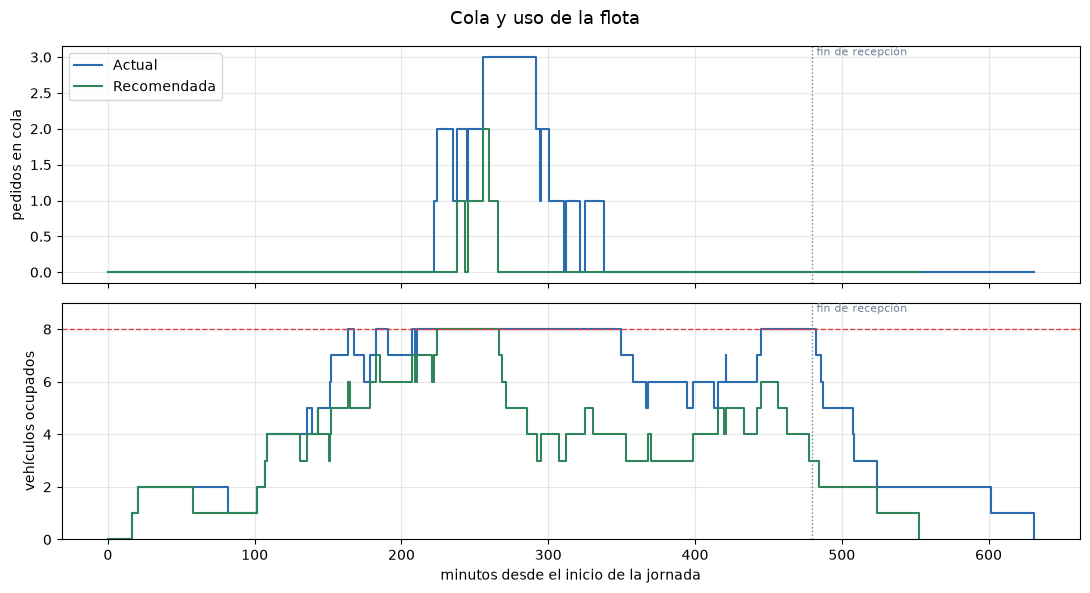

In [7]:
gr.estado_en_el_tiempo(resultados, p)
plt.show()

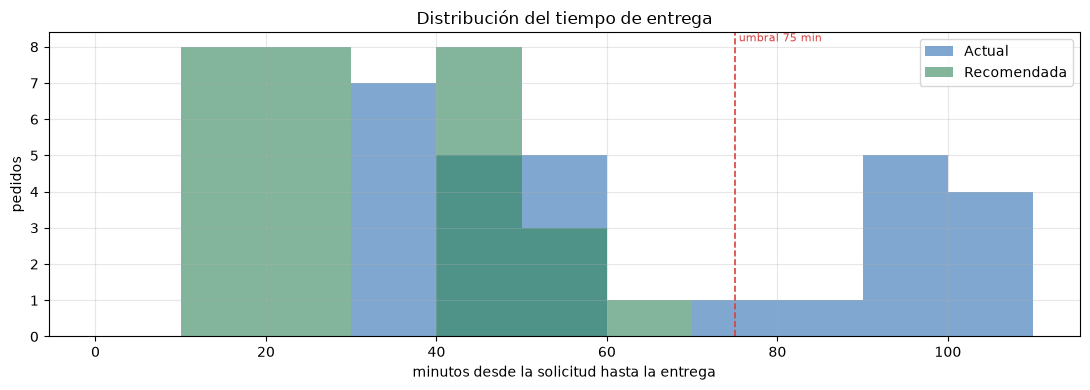

In [8]:
gr.distribucion_tiempos(resultados, p)
plt.show()

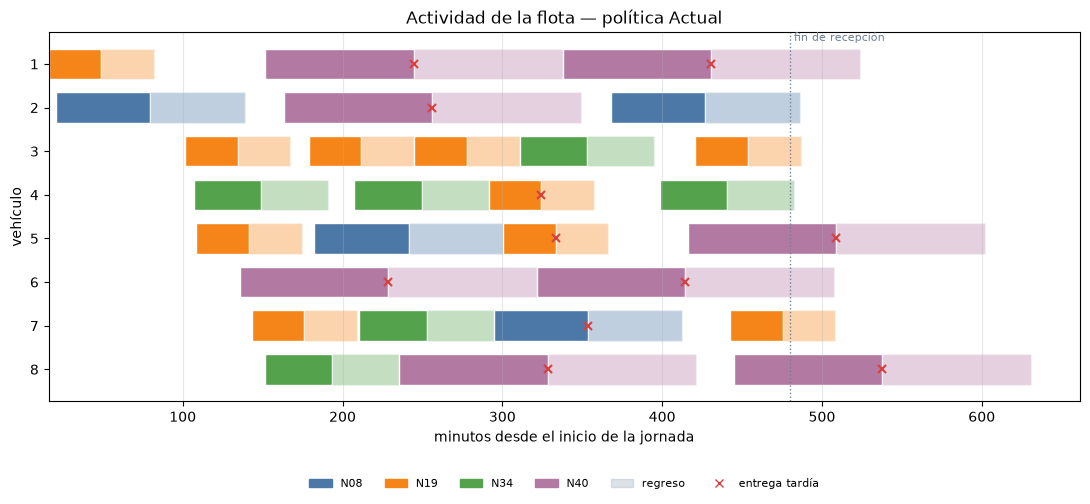

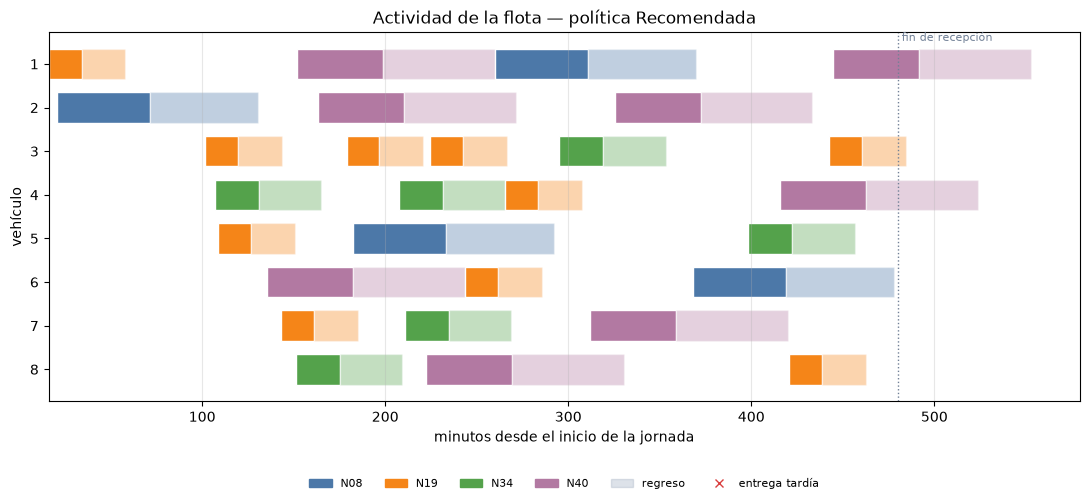

In [9]:
for politica, res in resultados.items():
    gr.gantt(res["registros"], p, titulo=f"Actividad de la flota — política {politica}")
    plt.show()

En el diagrama de cada vehículo, la barra fuerte es la ida y la tenue el regreso. Con la política actual las barras
son más largas (ciclos más largos) y aparecen muchas **x rojas** (entregas tardías), en especial en N40, cuya ida de
93 min ya supera el umbral.

### La simulación continúa después de las 8 horas

In [10]:
fin = p.horas_recepcion * 60
for politica, res in resultados.items():
    reg = res["registros"]
    pendientes = (reg["inicio"] > fin).sum()
    m = res["metricas"]
    print(f"{politica:>12}: último pedido recibido en t = {pedidos['llegada'].max():.1f} min; "
          f"{pendientes} pedidos salieron de la bodega después de t = {fin:g}; "
          f"última entrega en t = {reg['entrega'].max():.1f} "
          f"(+{m['tiempo adicional (min)']:.1f} min); último regreso en t = {m['fin de la operación (min)']:.1f}")

      Actual: último pedido recibido en t = 444.7 min; 0 pedidos salieron de la bodega después de t = 480; última entrega en t = 537.7 (+57.7 min); último regreso en t = 630.7
 Recomendada: último pedido recibido en t = 444.7 min; 0 pedidos salieron de la bodega después de t = 480; última entrega en t = 491.7 (+11.7 min); último regreso en t = 552.7


### Puntualidad por destino

In [11]:
pd.DataFrame({
    politica: res["registros"].assign(puntual=res["registros"]["solicitud_a_entrega"] <= p.umbral)
                              .groupby("destino")["puntual"].mean() * 100
    for politica, res in resultados.items()
}).rename_axis("destino").style.format("{:.0f} %")

,Actual,Recomendada
destino,,
N08,75 %,100 %
N19,80 %,100 %
N34,100 %,100 %
N40,0 %,100 %


## 5. Los tres escenarios (una corrida cada uno)

Una sola semilla no basta para concluir: el punto 7 repetirá cada escenario al menos 5 veces. Esta tabla solo muestra
cómo cambia el comportamiento al aumentar la demanda.

In [12]:
filas = {}
for escenario, tasa in s.ESCENARIOS.items():
    p_esc = s.Parametros(pedidos_por_hora=tasa, semilla=1)
    _, res, _ = s.comparar(p_esc, G)
    for politica, rr in res.items():
        filas[(escenario, politica)] = rr["metricas"]
escenarios = pd.DataFrame(filas).T
escenarios[["pedidos", "puntualidad (%)", "espera promedio (min)", "solicitud→entrega promedio (min)",
            "utilización (%)", "tiempo adicional (min)"]]

pedidos  puntualidad (%)  espera promedio (min)  \
Normal       Actual          28.0             60.7                    7.8   
             Recomendada     28.0            100.0                    1.1   
Semana Santa Actual          38.0             10.5                   71.7   
             Recomendada     38.0             86.8                    9.5   
Navidad      Actual          70.0             10.0                  237.1   
             Recomendada     70.0             18.6                   96.4   

                          solicitud→entrega promedio (min)  utilización (%)  \
Normal       Actual                                   63.6             61.9   
             Recomendada                              33.4             46.9   
Semana Santa Actual                                  136.0             81.6   
             Recomendada                              47.4             71.8   
Navidad      Actual                                  295.1             89.5   
             Recomendada                             131.3             89.1   

                          tiempo adicional (min)  
Normal       Actual                         57.7  
             Recomendada                    11.7  
Semana Santa Actual                        175.4  
             Recomendada                    29.1  
Navidad      Actual                        561.2  
             Recomendada                   240.2

## 6. Aplicación configurable (punto 6)

La aplicación `app.py` usa este mismo modelo. Se ejecuta con:

```bash
streamlit run app.py
```

Desde la interfaz se puede cambiar:

- **Escenario:** Normal (4/h), Semana Santa (6/h), Navidad (10/h) o personalizado.
- **Pedidos por hora**, **número de vehículos**, **horas de recepción**, **semilla** y **tiempo de descarga**.
- **Incidentes viales:** cambiar el tiempo de uno o varios tramos (congestión) o cerrarlos.

**Cómo se actualizan las rutas cuando cambia la red:** cada incidente modifica una copia del grafo (`rutas.aplicar_incidente`).
Con esa red, la política Recomendada vuelve a ejecutar Dijkstra para la ida y el regreso de cada destino, así que siempre usa
la mejor ruta disponible. La política Actual conserva las rutas de las hojas de despacho con los tiempos nuevos; si un
tramo cerrado forma parte de una de ellas, ese viaje se reemplaza por la ruta de menor tiempo y la app lo avisa.

## Conclusiones de este notebook

- El generador reproduce el proceso de Poisson del enunciado: tiempos exponenciales, ~8λ pedidos por día y destinos equiprobables.
- Con los **mismos pedidos**, la política recomendada mejora todas las métricas en el día normal de ejemplo: la puntualidad pasa
  de 61 % al 100 % y la espera casi desaparece.
- Con la política actual **ningún pedido a N40 es puntual**, aunque no espere: su ida de 93 min supera el umbral.
- Al subir la demanda, la ventaja de las rutas recomendadas se mantiene, pero en **Navidad la flota de 8 vehículos se satura**
  con ambas políticas: la utilización ronda el 90 %, la cola crece durante toda la jornada, menos de una de cada cinco
  entregas es puntual y la operación termina horas después del cierre de recepción.